# Custom operators and units

iBART can only find formulas its operators can build. This notebook shows how
operators and units work, how much the unit filter prunes, and how to add an
operator for your own domain.

An operator bundles four things that move in lockstep:

- a numeric function on JAX arrays,
- a SymPy function, so the descriptor stays symbolic,
- a validity predicate (for example `log` needs positive inputs),
- a unit rule (multiplying adds unit exponents; adding needs equal units).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
from jax_ibart import IBart, engineer
from jax_ibart.operators import Operator, BINARY, UNARY, default_unary, default_binary

print("default unary :", [op.name for op in default_unary()])
print("default binary:", [op.name for op in default_binary()])
print("also available:", sorted(set(UNARY) - {op.name for op in default_unary()}))

default unary : ['id', 'neg', 'sq', 'sqrt', 'log', 'exp', 'abs', 'sin', 'cos']
default binary: ['add', 'sub', 'mul', 'div', 'absdiff']
also available: ['inv']


## Units: a small example

Units are integer exponent vectors over base dimensions. Here `x` is a length and
`z` is a time, so `x + z` is rejected while `x*z` and `x/z` are allowed.

In [2]:
Xs = np.random.default_rng(0).uniform(1, 2, size=(12, 2))
units = np.array([[1, 0],   # x: [length, time] exponents
                  [0, 1]])  # z
pool = engineer.from_primary(Xs, ["x", "z"], units=units)

add = engineer.apply_binary(pool, [BINARY["add"]])
mul = engineer.apply_binary(pool, [BINARY["mul"]])
print("x + z generated:", add.n_descriptors, "(rejected: mismatched units)")
print("x * z generated:", mul.n_descriptors, "-> unit", mul.units[0].tolist())

x + z generated: 0 (rejected: mismatched units)
x * z generated: 1 -> unit [1, 1]


## How much the unit filter prunes on real data

On the 59 catalysis features, one round of binary operators builds the
following number of descriptors without units and with them:

without units: 11,370   with units: 3,570


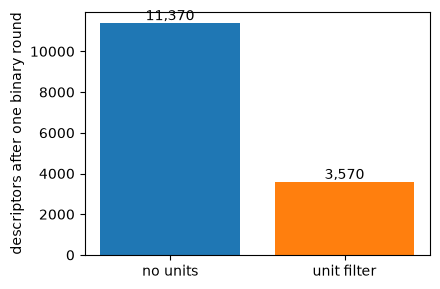

In [3]:
from jax_ibart.datasets import load_metal_support

Xc, yc, cnames, cunits = load_metal_support()
n_plain = engineer.apply_binary(engineer.from_primary(Xc, cnames), default_binary()).n_descriptors
n_units = engineer.apply_binary(engineer.from_primary(Xc, cnames, units=cunits),
                                default_binary()).n_descriptors
print(f"without units: {n_plain:,}   with units: {n_units:,}")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["no units", "unit filter"], [n_plain, n_units], color=["C0", "C1"])
for i, v in enumerate([n_plain, n_units]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_ylabel("descriptors after one binary round")
fig.tight_layout()
plt.show()

The filter removes about two thirds of the candidates before any screening, and
every one it removes is physically meaningless. That makes the screen's job
easier and the result more trustworthy.

One caveat: as in the R iBART package, `sqrt`, `log`, `exp`, `sin` and `cos`
return a unitless result. So the filter mainly constrains addition and
subtraction, and a descriptor like `sqrt(a) - sqrt(M)` can pass even when `a`
and `M` have different units.

## Adding your own operator: the Stefan-Boltzmann law

Radiated power goes as `T^4`. The default unary operators include `x^2` but not
`x^4`, so in one unary round iBART cannot build `T^4`. We generate data with two
distractor features and fit with the default operators first.

In [4]:
rng = np.random.default_rng(0)
n = 80
T = rng.uniform(300, 1500, n)     # temperature, K
P = rng.uniform(1, 10, n)         # pressure (irrelevant)
d = rng.uniform(0, 1, n)          # size (irrelevant)
j = 5.670e-8 * T**4 * (1 + rng.normal(0, 0.01, n))   # W/m^2, 1% noise
Xsb = np.column_stack([T, P, d])
sb_names = ["T", "P", "d"]

def r2(m):
    p = m.predict(Xsb)
    return 1 - ((j - p) ** 2).sum() / ((j - j.mean()) ** 2).sum()

default = IBart(backend="diff", schedule=("u",), max_dim=1, seed=0,
                steps=1500).fit(Xsb, j, sb_names)
print("default operators:", default.descriptors_, f"R^2 = {r2(default):.5f}")

default operators: [T**2] R^2 = 0.93647


Now define a `pow4` operator and pass it in with `unary_ops`:

In [5]:
pow4 = Operator(
    name="pow4", arity=1,
    fn=lambda x: x ** 4,                          # numeric (JAX)
    sym=lambda e: e ** 4,                         # symbolic (SymPy)
    valid=lambda x: jnp.ones(x.shape[-1], bool),  # valid everywhere
    unit=lambda u: 4 * u,                         # K -> K^4
)
custom = IBart(backend="diff", schedule=("u",), max_dim=1, seed=0, steps=1500,
               unary_ops=default_unary() + [pow4]).fit(Xsb, j, sb_names)
print("with pow4        :", custom.descriptors_, f"R^2 = {r2(custom):.5f}")
print(f"fitted constant  : {custom.coef_[1]:.4g}  (Stefan-Boltzmann 5.670e-8)")

with pow4        : [T**4] R^2 = 0.99977
fitted constant  : 5.669e-08  (Stefan-Boltzmann 5.670e-8)


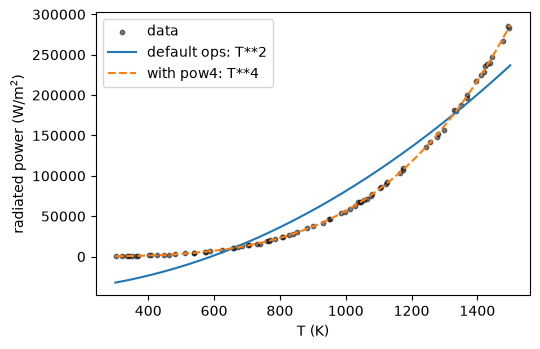

In [6]:
Tg = np.linspace(300, 1500, 200)
Xg = np.column_stack([Tg, np.full_like(Tg, 5), np.full_like(Tg, 0.5)])
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.scatter(T, j, s=10, color="k", alpha=0.5, label="data")
ax.plot(Tg, default.predict(Xg), label=f"default ops: {default.descriptors_[0]}")
ax.plot(Tg, custom.predict(Xg), "--", label=f"with pow4: {custom.descriptors_[0]}")
ax.set_xlabel("T (K)")
ax.set_ylabel("radiated power (W/m$^2$)")
ax.legend()
fig.tight_layout()
plt.show()

With the default operators the best iBART can do is a quadratic, which misses
at both ends. With `pow4` it finds `T^4` and recovers the Stefan-Boltzmann
constant. `binary_ops` works the same way for two-argument operators.

The lesson generalizes: put the functional forms you expect from physics into
the operator set, and let iBART decide which variables they act on.